In [13]:
import pvlib
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS
import math

In [14]:
# SOURCES AND COSTS ############################
SOURCE_PVGIS = "../data/pgvis_data_2018_2020.csv"
SANDIA_MODULE_NAME = "Canadian_Solar_CS6X_300M__2013_"
CEC_INVERTER_NAME = "Siemens_Industry__SINVERT_PVM20_UL__480V_"

modules_per_string = math.floor(720 / 43.5918)
strings_per_array = math.floor(20118 / ((8.1359 * 34.9531) * modules_per_string))

LAT = 33.448437
LONG = -112.074141
TZ = "America/Phoenix"

modules_per_string, strings_per_array

(16, 4)

In [10]:
# LOCATION #####################################
location = pvlib.location.Location(
    latitude=LAT,
    longitude=LONG,
    tz=TZ,
)

In [11]:
# Module and Inverter ##########################
# TODO: design PV System and choose module and inverter
# custom modules can also be used
# ref: https://youtu.be/atXfLEJxl18?si=4y7tW2bmU7YiKUZJ & https://youtu.be/prhQf0rP3g8?si=MXsBysuF4-1S8pJw
modules_db = pvlib.pvsystem.retrieve_sam("SandiaMod")
inverters_db = pvlib.pvsystem.retrieve_sam("CECInverter")

modules_db.to_csv("../data/sandia-mod.csv")

module = modules_db[SANDIA_MODULE_NAME]
inverter = inverters_db[CEC_INVERTER_NAME]

module, inverter

(Vintage                                                          2013
 Area                                                             1.91
 Material                                                         c-Si
 Cells_in_Series                                                    72
 Parallel_Strings                                                    1
 Isco                                                           8.6388
 Voco                                                          43.5918
 Impo                                                           8.1359
 Vmpo                                                          34.9531
 Aisc                                                           0.0005
 Aimp                                                          -0.0001
 C0                                                             1.0121
 C1                                                            -0.0121
 Bvoco                                                         -0.1532
 Mbvoc

In [23]:
# System #######################################
# TODO: choose the right temperature model for pv
temperature_parameters = TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

# TODO: update modules_per_inverter and modules_per_string
system = pvlib.pvsystem.PVSystem(
    module_parameters=module,
    inverter_parameters=inverter,
    temperature_model_parameters=temperature_parameters,
    modules_per_string=modules_per_string,
    strings_per_inverter=strings_per_array,
)


In [24]:
# Weather Data #################################
weather_data, _, metadata = pvlib.iotools.read_pvgis_hourly(
    SOURCE_PVGIS, map_variables=True
)
weather_data["poa_diffuse"] = (
    weather_data["poa_ground_diffuse"] + weather_data["poa_sky_diffuse"]
)
weather_data["poa_global"] = weather_data["poa_direct"] + weather_data["poa_diffuse"]

weather_data

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int,poa_diffuse,poa_global
time,,,,,,,,,
2018-01-01 00:30:00+00:00,0.00,0.00,0.00,-0.64,20.16,0.41,0,0.00,0.00
2018-01-01 01:30:00+00:00,0.00,0.00,0.00,0.00,18.81,0.55,0,0.00,0.00
2018-01-01 02:30:00+00:00,0.00,0.00,0.00,0.00,17.80,0.41,0,0.00,0.00
2018-01-01 03:30:00+00:00,0.00,0.00,0.00,0.00,16.81,0.55,0,0.00,0.00
2018-01-01 04:30:00+00:00,0.00,0.00,0.00,0.00,15.77,0.83,0,0.00,0.00
...,...,...,...,...,...,...,...,...,...
2020-12-31 19:30:00+00:00,360.46,281.19,7.16,33.45,12.81,2.28,0,288.35,648.81
2020-12-31 20:30:00+00:00,297.81,269.36,6.52,31.74,14.03,2.14,0,275.88,573.69
2020-12-31 21:30:00+00:00,70.97,216.43,4.08,26.76,14.82,1.45,0,220.51,291.48


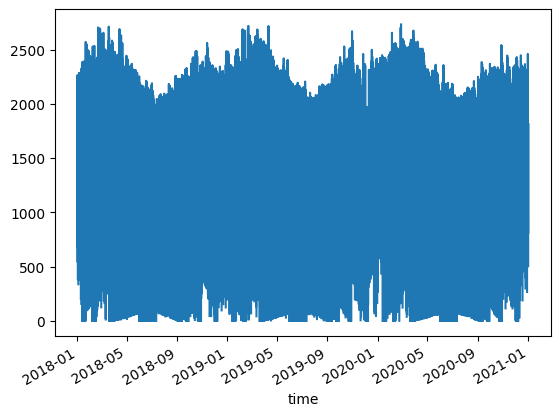

In [25]:
# Model Chain ##################################
model_chain = pvlib.modelchain.ModelChain(system=system, location=location)
model_chain.run_model_from_poa(weather_data)
if model_chain.results.ac is not None:
    model_chain.results.ac.plot()
